# Ranking analysis — which features are worth using?

**Question (a)**: the day before a season starts, predict the final regular-season ranking of every
team *inside its conference* (two rankings of ~15 teams per season, ordered by points).

This notebook decides **what goes into the models** in `ranking_comparison.ipynb`. Every decision is
made on seasons **before 2005** (`TEST_START_YEAR`); 2005–2009 is kept for the final, clean evaluation.

The analysis has three layers:

1. **Base team history** — previous points, longer history, trend, goals, playoffs, coach.
2. **External tables** — shots, save %, special teams, goalie, roster composition, coach record,
   playoff history, awards, home/road and second-half splits.
3. **Selection** — keep the blocks that actually improve the walk-forward rank MAE.

> **Protocol in one line**: for each season *Y*, train on every season `< Y` and predict *Y*.
> Never use information from *Y* or later.

## 1. Data and feature blocks

The base dataset is `data_prepared/teams.csv` (prepared by `data_preparation.ipynb`). The external
features are built from the raw tables:

| File | What it contributes |
|---|---|
| `data/Teams.csv` | goals, special teams, penalties |
| `data/Scoring.csv` | team shots, player points, positions |
| `data/Goalies.csv` | team save %, starter workload and quality |
| `data/Master.csv` | player age |
| `data/Coaches.csv` | coach career record and tenure |
| `data/SeriesPost.csv`, `data/TeamsPost.csv` | playoff history |
| `data/AwardsPlayers.csv` | awards won by the previous roster |
| `data/TeamSplits.csv` | home/road and second-half performance |

All performance features are lagged: the value of season *Y-1* predicts season *Y*. The roster block
uses the players who actually played for the team in season *Y* (in-season arrivals included), so it
is a mild upper bound rather than a strict day-before-the-season forecast. This caveat is repeated in
the conclusions.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance

# Make the helper modules importable whether the notebook is run from the project root
# or from the ranking/ directory.
for candidate in [Path.cwd(), Path.cwd() / "ranking"]:
    if (candidate / "ranking_utils.py").exists():
        sys.path.insert(0, str(candidate))
        break

import ranking_utils as ru
import ranking_features as rf

teams = ru.load_teams()
df = ru.build_dataset(teams)
groups = ru.feature_groups(df)

ext, EXT_GROUPS = rf.build_external_features(ru.DATA_DIR)
df = df.merge(ext.drop(columns=["franchID"]), on=["year", "tmID"], how="left")
EXT_COLS = [c for cols in EXT_GROUPS.values() for c in cols]
df[EXT_COLS] = df[EXT_COLS].fillna(0.0)

ALL_GROUPS = {**groups, **EXT_GROUPS}
ALL_FEATURES = ru.flatten(ALL_GROUPS)

BASE_GROUPS = ["prev_points", "coach", "history_points"]
BASE_FEATURES = ru.flatten(groups, BASE_GROUPS)

dev = df[df["year"] < ru.TEST_START_YEAR].copy()
SELECTION_YEARS = [y for y in sorted(dev["year"].unique()) if y >= 1995]

print(f"{len(df)} team-seasons, {df['year'].min()}-{df['year'].max()}")
print(f"Development part (<{ru.TEST_START_YEAR}): {len(dev)} rows | selection years: {SELECTION_YEARS[0]}-{SELECTION_YEARS[-1]}")
print(f"\nBase feature groups ({len(BASE_FEATURES)} features):")
for name in BASE_GROUPS:
    print(f"  {name:15s} {groups[name]}")
print(f"\nExternal feature blocks ({len(EXT_COLS)} features):")
for name, cols in EXT_GROUPS.items():
    print(f"  {name:15s} {len(cols):2d} features")

732 team-seasons, 1980-2009
Development part (<2005): 582 rows | selection years: 1995-2003

Base feature groups (8 features):
  prev_points     ['pts_z_lag1']
  coach           ['coach_changed']
  history_points  ['pts_z_lag2', 'pts_z_lag3', 'pts_z_lag4', 'pts_z_lag5', 'pts_z_mean3', 'pts_z_mean5']

External feature blocks (35 features):
  shots_luck       7 features
  special_teams    3 features
  goalie           5 features
  roster           7 features
  coach_record     3 features
  playoff_history  4 features
  awards           3 features
  splits           3 features


## 2. Data quality and target

Points are not comparable across eras (80 vs 82 games, ties then overtime losses, shootouts), and the
prepared file is MinMax-normalised. We therefore predict the **league-wide z-score of the season
points** (`target`) and only turn it into a rank at the very end, by sorting inside each
`(year, conference)`. Ties in points are broken by wins, then team id.

In [2]:
all_years = set(range(int(df["year"].min()), int(df["year"].max()) + 1))
print("Missing seasons:", sorted(all_years - set(df["year"])))   # 2004 = lockout
print("Rows without conference:", int(df["confID"].eq("NONE").sum()))

sizes = df.groupby(["year", "confID"]).size().unstack(fill_value=0)
print("\nTeams per conference (last seasons):")
display(sizes.tail(8))

print("\nMissing values in the raw inputs used:")
raw_cols = [c for c in ["Pts", "W", "GF", "GA", "playoff"] + ru.COACH_COLUMNS if c in teams.columns]
display(teams[raw_cols].isna().mean().round(3).to_frame("missing_rate"))

print(f"\nTeam-seasons without any history: {(df['n_hist'] == 0).mean():.1%}")

Missing seasons: [2004]
Rows without conference: 0

Teams per conference (last seasons):


confID,CC,EC,WA,WC
year,,,,
2001,0,15,0,15
2002,0,15,0,15
2003,0,15,0,15
2005,0,15,0,15
2006,0,15,0,15
2007,0,15,0,15
2008,0,15,0,15
2009,0,15,0,15



Missing values in the raw inputs used:


,missing_rate
Pts,0.000
W,0.000
GF,0.000
GA,0.000
playoff,0.366
coach_changed,0.000



Team-seasons without any history: 4.1%


In [3]:
season = df[df["year"] == df["year"].max()][["confID", "conf_rank", "tmID", "target", "Pts"]]
print(f"Example - actual ranking of {df['year'].max()}:")
display(season.sort_values(["confID", "conf_rank"]).head(8))

ties = df.groupby(["year", "confID"])["Pts"].apply(lambda s: s.duplicated().sum()).sum()
print(f"Tied point totals inside a conference over the whole data: {int(ties)}")

Example - actual ranking of 2009:


,confID,conf_rank,tmID,target,Pts
702,EC,1,WAS,2.236902,0.907407
703,EC,2,NJD,0.846882,0.740741
704,EC,3,PIT,0.692436,0.722222
705,EC,4,BUF,0.615212,0.712963
706,EC,5,OTT,0.151872,0.657407
707,EC,6,BOS,-0.079797,0.629630
708,EC,7,PHI,-0.311467,0.601852
709,EC,8,MTL,-0.311467,0.601852


Tied point totals inside a conference over the whole data: 65


## 3. How persistent are the rankings?

If last season's points explain most of this season's, the naive model is hard to beat and extra
features can only bring marginal gains. Hockey is known for high parity (and luck), so we expect a
moderate correlation.

,lag (seasons back),spearman with target,n
0,1,0.587,552
1,2,0.502,522
2,3,0.385,492
3,4,0.293,462
4,5,0.158,434


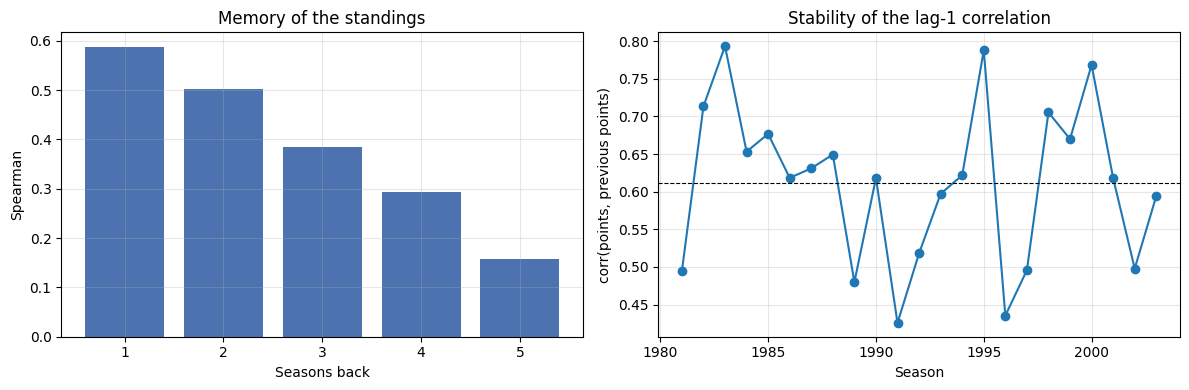

Regression to the mean: target = 0.024 + 0.601 * previous points z-score
-> only ~60% of last season's deviation from the league average is kept.


In [4]:
rows = []
for k in range(1, ru.LAGS + 1):
    sub = dev[dev["n_hist"] >= k]
    rows.append({"lag (seasons back)": k,
                 "spearman with target": sub["target"].corr(sub[f"pts_z_lag{k}"], method="spearman"),
                 "n": len(sub)})
persistence = pd.DataFrame(rows)
display(persistence.round(3))

by_year = {}
for year, g in dev[dev["n_hist"] >= 1].groupby("year"):
    by_year[year] = g["target"].corr(g["pts_z_lag1"])
by_year = pd.Series(by_year)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(persistence["lag (seasons back)"], persistence["spearman with target"], color="#4C72B0")
axes[0].set_xlabel("Seasons back"); axes[0].set_ylabel("Spearman")
axes[0].set_title("Memory of the standings"); axes[0].grid(alpha=.3)
axes[1].plot(by_year.index, by_year.values, marker="o")
axes[1].axhline(by_year.mean(), color="k", ls="--", lw=.8)
axes[1].set_xlabel("Season"); axes[1].set_ylabel("corr(points, previous points)")
axes[1].set_title("Stability of the lag-1 correlation"); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

sub = dev[dev["n_hist"] >= 1]
slope, intercept = np.polyfit(sub["pts_z_lag1"], sub["target"], 1)
print(f"Regression to the mean: target = {intercept:.3f} + {slope:.3f} * previous points z-score")
print(f"-> only ~{slope:.0%} of last season's deviation from the league average is kept.")

## 4. Which history window is useful?

Simple, parameter-free scores used to rank teams inside each conference on the selection years:
last season only, mean of 2, 3 and 5 seasons, and exponentially decaying weights.

In [5]:
def evaluate_scores(pred):
    ranked = ru.rank_predictions(pred, df)
    return ru.summarise(ru.season_metrics(ranked))

candidates = {"last season": "pts_z_lag1", "mean 2 seasons": "pts_z_mean2",
              "mean 3 seasons": "pts_z_mean3", "mean 5 seasons": "pts_z_mean5",
              "exp. decay (0.5)": "pts_z_ewm"}
window_table = pd.DataFrame({
    name: evaluate_scores(ru.baseline_scores(df[df["year"] < ru.TEST_START_YEAR], col, SELECTION_YEARS))
    for name, col in candidates.items()
}).T
print(f"Random ranking of 15 teams: MAE = {ru.random_ranking_mae(15):.2f}, top-8 overlap = {8/15:.2f}")
display(window_table.round(3))

lag_cols = [f"pts_z_lag{k}" for k in range(1, ru.LAGS + 1)]
train_ols = dev[(dev["year"] < SELECTION_YEARS[0]) & (dev["n_hist"] >= ru.LAGS)]
if len(train_ols):
    ols = make_pipeline(StandardScaler(), Ridge(alpha=1e-6)).fit(train_ols[lag_cols], train_ols["target"])
    print("Linear weights on the 5 previous seasons (fit before the selection years):")
    print({c: round(float(w), 3) for c, w in zip(lag_cols, ols[-1].coef_)})

Random ranking of 15 teams: MAE = 4.98, top-8 overlap = 0.53


,mae,rmse,spearman,top_overlap,within_2
last season,2.904,3.725,0.561,0.712,0.536
mean 2 seasons,2.695,3.488,0.605,0.721,0.577
mean 3 seasons,2.912,3.668,0.563,0.694,0.536
mean 5 seasons,3.216,4.028,0.490,0.677,0.460
exp. decay (0.5),2.862,3.668,0.571,0.721,0.558


Linear weights on the 5 previous seasons (fit before the selection years):
{'pts_z_lag1': 0.382, 'pts_z_lag2': 0.223, 'pts_z_lag3': -0.013, 'pts_z_lag4': 0.064, 'pts_z_lag5': -0.111}


## 5. Which features carry signal?

### 5.1 Univariate signal

Spearman correlation of each feature with the season points z-score, on development seasons only.
The bars are coloured by block; the table keeps the 15 strongest features.

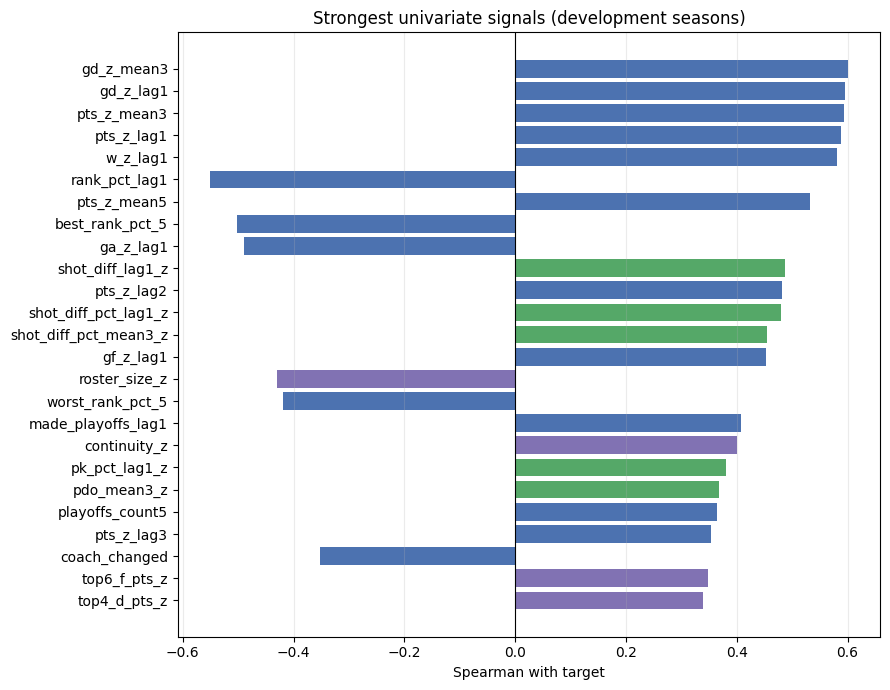

,block,spearman
gd_z_mean3,goals,0.601
gd_z_lag1,goals,0.596
pts_z_mean3,history_points,0.594
pts_z_lag1,prev_points,0.587
w_z_lag1,wins,0.580
rank_pct_lag1,rank_history,-0.551
pts_z_mean5,history_points,0.532
best_rank_pct_5,rank_history,-0.502
ga_z_lag1,goals,-0.490
shot_diff_lag1_z,shots_luck,0.488


In [6]:
sub = dev[dev["n_hist"] >= 1]
corr = pd.Series({f: sub[f].corr(sub["target"], method="spearman") for f in ALL_FEATURES})
block = {}
for name, cols in ALL_GROUPS.items():
    for c in cols:
        block[c] = name
colors = {"prev_points": "#4C72B0", "history_points": "#4C72B0", "trend": "#4C72B0",
          "rank_history": "#4C72B0", "goals": "#4C72B0", "wins": "#4C72B0",
          "playoffs": "#4C72B0", "coach": "#4C72B0", "experience": "#4C72B0",
          "roster": "#8172B3", "shots_luck": "#55A868", "goalie": "#55A868",
          "special_teams": "#55A868", "coach_record": "#55A868",
          "playoff_history": "#55A868", "awards": "#55A868", "splits": "#55A868"}

top = corr.reindex(corr.abs().sort_values(ascending=False).head(25).index)
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top.index[::-1], top.values[::-1],
        color=[colors.get(block[c], "#8C8C8C") for c in top.index[::-1]])
ax.axvline(0, color="black", lw=.8)
ax.set_xlabel("Spearman with target")
ax.set_title("Strongest univariate signals (development seasons)")
ax.grid(axis="x", alpha=.25)
plt.tight_layout(); plt.show()

table = pd.DataFrame({
    "block": [block[c] for c in corr.abs().sort_values(ascending=False).head(15).index],
    "spearman": corr.reindex(corr.abs().sort_values(ascending=False).head(15).index).round(3),
})
display(table)

### 5.2 Collinearity

The heatmap focuses on the blocks that are candidates for the final model: base history, roster
composition and shots/luck. Pairs with `|corr| > 0.9` are redundant for a linear model.

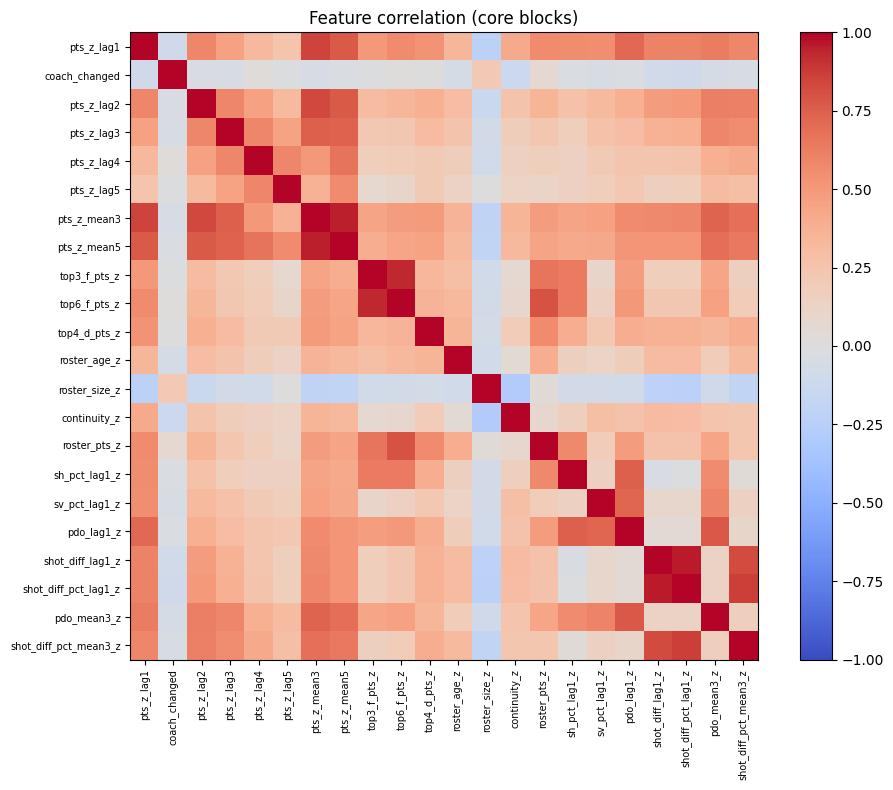

Pairs with |corr| > 0.9:
  shot_diff_lag1_z       shot_diff_pct_lag1_z   +0.96
  pts_z_mean3            pts_z_mean5            +0.95
  top3_f_pts_z           top6_f_pts_z           +0.93


In [7]:
core = BASE_FEATURES + EXT_GROUPS["roster"] + EXT_GROUPS["shots_luck"]
cm = sub[core].corr()
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(cm.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(cm))); ax.set_xticklabels(cm.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(cm))); ax.set_yticklabels(cm.columns, fontsize=7)
fig.colorbar(im); ax.set_title("Feature correlation (core blocks)"); plt.tight_layout(); plt.show()

pairs = [(a, b, cm.loc[a, b]) for i, a in enumerate(cm.columns)
         for b in cm.columns[i + 1:] if abs(cm.loc[a, b]) > 0.9]
print("Pairs with |corr| > 0.9:")
for a, b, c in sorted(pairs, key=lambda t: -abs(t[2])):
    print(f"  {a:22s} {b:22s} {c:+.2f}")

## 6. External blocks: incremental value

For each external block, we add it to the base team-history features and compare the walk-forward MAE
on the selection years (1995–2004). The confidence interval is a paired bootstrap over whole
`(season, conference)` rankings. A block is interesting only if the interval is clearly above 0.

In [8]:
ridge = lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 30)))


def evaluate(features, years):
    pred = ru.walk_forward(df, ridge, features, years)
    ranked = ru.rank_predictions(pred, df)
    return ru.summarise(ru.season_metrics(ranked)), ranked


def gain_vs_base(features, base_ranked, years):
    _, ranked = evaluate(features, years)
    key = ["year", "tmID"]
    b = base_ranked.set_index(key).sort_index()
    r = ranked.set_index(key).sort_index()
    gid = (b["confID"] + "-" + b.index.get_level_values("year").astype(str)).to_numpy()
    gain, (lo, hi) = ru.paired_bootstrap(
        b["abs_err"].to_numpy(), r["abs_err"].reindex(b.index).to_numpy(), gid)
    return gain, lo, hi


base_summary, base_ranked = evaluate(BASE_FEATURES, SELECTION_YEARS)
rows = [{"block": "base (history + coach)", "n": len(BASE_FEATURES),
         "mae": base_summary["mae"], "spearman": base_summary["spearman"],
         "gain": 0.0, "ci_low": 0.0, "ci_high": 0.0}]
for name, cols in EXT_GROUPS.items():
    s, _ = evaluate(BASE_FEATURES + cols, SELECTION_YEARS)
    gain, lo, hi = gain_vs_base(BASE_FEATURES + cols, base_ranked, SELECTION_YEARS)
    rows.append({"block": name, "n": len(cols), "mae": s["mae"], "spearman": s["spearman"],
                 "gain": gain, "ci_low": lo, "ci_high": hi})
incremental = pd.DataFrame(rows).sort_values("mae")
incremental["significant"] = incremental["ci_low"] > 0
display(incremental.round(3).set_index("block"))

,n,mae,spearman,gain,ci_low,ci_high,significant
block,,,,,,,
roster,7,2.162,0.747,0.372,0.127,0.640,True
shots_luck,7,2.456,0.678,0.071,-0.054,0.213,False
awards,3,2.473,0.663,0.055,-0.024,0.141,False
base (history + coach),8,2.524,0.661,0.000,0.000,0.000,False
playoff_history,4,2.524,0.662,0.000,-0.092,0.077,False
special_teams,3,2.524,0.658,0.000,-0.038,0.040,False
coach_record,3,2.557,0.658,-0.032,-0.091,0.015,False
goalie,5,2.571,0.657,-0.040,-0.206,0.119,False
splits,3,2.598,0.648,-0.079,-0.173,0.008,False


**Reading the table.**

* **Roster composition** is the only block with a large, clearly significant gain. The signal comes
  from the quality of the players on the roster (top-3 / top-6 forwards, top-4 defencemen), their
  age, the number of regulars and continuity. This is the main external lever.
* **Shots / luck** brings a small positive gain, consistent with shot differential and PDO carrying
  information beyond points.
* **Special teams, goalie, coach record, playoffs, awards and splits** are neutral or negative once
  the roster and last season's points are in the model. They are not selected.
* The roster block uses the actual season roster (in-season arrivals included), so its gain is an
  upper bound for a strict day-before-the-season forecast.

## 7. Non-linear importance

A shallow gradient boosting is trained on the oldest seasons and evaluated on the following ones.
Permutation importance measures how much validation R² drops when a feature is shuffled. This checks
that the linear selection is not missing a non-linear signal.

train rows: 381 | validation rows: 171 | R2 on validation: 0.600


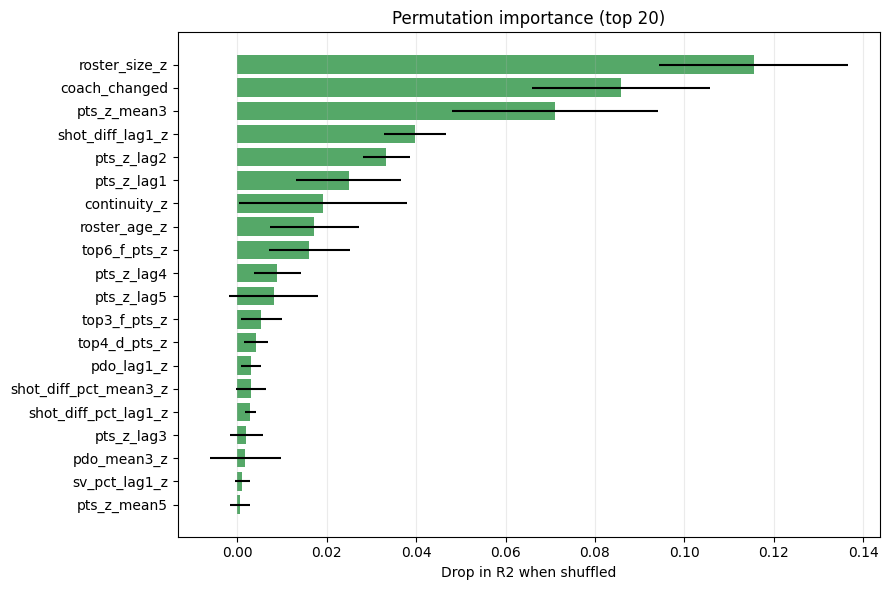

In [9]:
model_features = BASE_FEATURES + EXT_GROUPS["roster"] + EXT_GROUPS["shots_luck"]
train = dev[(dev["year"] < 1998) & (dev["n_hist"] >= 1)]
valid = dev[(dev["year"] >= 1998) & (dev["n_hist"] >= 1)]
gbm = HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=200,
                                    min_samples_leaf=20, l2_regularization=1.0,
                                    random_state=ru.RANDOM_STATE)
gbm.fit(train[model_features], train["target"])
print(f"train rows: {len(train)} | validation rows: {len(valid)} | "
      f"R2 on validation: {gbm.score(valid[model_features], valid['target']):.3f}")

pi = permutation_importance(gbm, valid[model_features], valid["target"],
                            n_repeats=20, random_state=ru.RANDOM_STATE)
importance = pd.Series(pi.importances_mean, index=model_features).sort_values()
top_imp = importance.tail(20)
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top_imp.index, top_imp.values,
        xerr=pd.Series(pi.importances_std, index=model_features).reindex(top_imp.index),
        color="#55A868")
ax.set_xlabel("Drop in R2 when shuffled")
ax.set_title("Permutation importance (top 20)")
ax.grid(axis="x", alpha=.25)
plt.tight_layout(); plt.show()

## 8. Feature-group selection

Greedy forward selection, starting from last season's points. At each step we add the block that most
reduces the walk-forward rank MAE on 1995–2004, and stop when the gain is below `MIN_GAIN` rank
positions. The selection uses only pre-2005 seasons; 2005–2009 is never touched here.

In [10]:
MIN_GAIN = 0.01


def selection_mae(group_names):
    features = ru.flatten(ALL_GROUPS, group_names)
    pred = ru.walk_forward(df[df["year"] < ru.TEST_START_YEAR], ridge, features, SELECTION_YEARS)
    ranked = ru.rank_predictions(pred, df)
    return ru.season_metrics(ranked)["mae"].mean()


selected = ["prev_points"]
best_mae = selection_mae(selected)
steps = [{"added": "prev_points", "mae": best_mae}]
remaining = [g for g in ALL_GROUPS if g not in selected]

while remaining:
    trials = {g: selection_mae(selected + [g]) for g in remaining}
    candidate = min(trials, key=trials.get)
    print(f"selected={selected} (MAE {best_mae:.3f}) -> best addition: {candidate} ({trials[candidate]:.3f})")
    if best_mae - trials[candidate] < MIN_GAIN:
        break
    selected.append(candidate)
    best_mae = trials[candidate]
    steps.append({"added": candidate, "mae": best_mae})
    remaining.remove(candidate)

display(pd.DataFrame(steps).round(3))
selected_features = ru.flatten(ALL_GROUPS, selected)
print("\nSelected groups  :", selected)
print("Selected features:", selected_features)

with open(ru.SELECTED_FEATURES_PATH, "w") as f:
    json.dump({
        "selected_groups": selected,
        "features": selected_features,
        "base_groups": BASE_GROUPS,
        "base_features": BASE_FEATURES,
    }, f, indent=2)
print(f"Saved -> {ru.SELECTED_FEATURES_PATH.name}")

selected=['prev_points'] (MAE 2.904) -> best addition: roster (2.395)


selected=['prev_points', 'roster'] (MAE 2.395) -> best addition: shots_luck (2.284)


selected=['prev_points', 'roster', 'shots_luck'] (MAE 2.284) -> best addition: coach (2.136)


selected=['prev_points', 'roster', 'shots_luck', 'coach'] (MAE 2.136) -> best addition: splits (2.136)


,added,mae
0,prev_points,2.904
1,roster,2.395
2,shots_luck,2.284
3,coach,2.136



Selected groups  : ['prev_points', 'roster', 'shots_luck', 'coach']
Selected features: ['pts_z_lag1', 'top3_f_pts_z', 'top6_f_pts_z', 'top4_d_pts_z', 'roster_age_z', 'roster_size_z', 'continuity_z', 'roster_pts_z', 'sh_pct_lag1_z', 'sv_pct_lag1_z', 'pdo_lag1_z', 'shot_diff_lag1_z', 'shot_diff_pct_lag1_z', 'pdo_mean3_z', 'shot_diff_pct_mean3_z', 'coach_changed']
Saved -> selected_features.json


## 9. Conclusions

**What is worth using**

| Block | Verdict | Why |
|---|---|---|
| Previous points (`pts_z_lag1`) | keep | strongest single history signal |
| Longer history (`lag2`–`lag5`, means) | only if no roster | mostly redundant once roster composition is included |
| Coach changed | keep | cheap, known before the season |
| Roster composition | **keep** | top-6 forwards, top-4 defence, age, size, continuity: large significant gain |
| Shots / luck (PDO, shot differential) | keep if it survives selection | small but positive; captures repeatable shot quality |
| Special teams, goalie, coach record, playoffs, awards, splits | drop | neutral or negative beyond the blocks above |

**What this means for the models**

* The best feature set is **short**: last season's points, coach change, roster composition and a
  small shots/luck block. The comparison notebook uses exactly this set for its external models.
* The external gain is **not a model-class effect**: it comes from better information, not from a
  more complex algorithm. This is why the comparison notebook keeps simple, regularised models.
* **Roster caveat**: the roster block uses the players who actually played in the season, so it
  includes in-season arrivals. Treat its performance as an upper bound; a strict forecast would use
  the roster known at training camp.
* **Data caveat**: all "external" features are still internal to the provided hockey tables. Market
  information (preseason win totals, injuries, payroll) is not available here and is the next real
  lever for a larger gain.
* **Validation caveat**: the selection uses 1995–2004. The comparison notebook keeps 2005–2009 as the
  clean test and adds a 1995–2009 backtest as a stability/power check.